In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Titanic dataset

df = sns.load_dataset("titanic")

# Display first 5 rows
print("FIRST FIVE ROWS")
print(df.head())

FIRST FIVE ROWS
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [3]:
df = sns.load_dataset("titanic")

In [4]:
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [5]:
# Select important columns

df = df[["survived", "pclass", "sex", "age", "fare"]]

# Display first five rows
print("SELECTED COLUMNS")
print(df.head())

# Check dataset shape
print("\nDATASET SHAPE")
print(df.shape)

SELECTED COLUMNS
   survived  pclass     sex   age     fare
0         0       3    male  22.0   7.2500
1         1       1  female  38.0  71.2833
2         1       3  female  26.0   7.9250
3         1       1  female  35.0  53.1000
4         0       3    male  35.0   8.0500

DATASET SHAPE
(891, 5)


In [7]:
# Select important columns

df = df[["survived", "pclass", "sex", "age", "fare"]]

print("SELECTED COLUMNS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

SELECTED COLUMNS
   survived  pclass     sex   age     fare
0         0       3    male  22.0   7.2500
1         1       1  female  38.0  71.2833
2         1       3  female  26.0   7.9250
3         1       1  female  35.0  53.1000
4         0       3    male  35.0   8.0500

DATASET SHAPE
(891, 5)


In [8]:
# Check missing values

print("MISSING VALUES")
print(df.isnull().sum())

MISSING VALUES
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64


In [9]:
# Remove missing values

df = df.dropna()

print("DATA AFTER CLEANING")
print(df.isnull().sum())

print("\nNEW DATASET SHAPE")
print(df.shape)

DATA AFTER CLEANING
survived    0
pclass      0
sex         0
age         0
fare        0
dtype: int64

NEW DATASET SHAPE
(714, 5)


In [10]:
# Convert gender into numerical values

df["sex"] = (df["sex"] == "female").astype(int)

print("GENDER CONVERTED SUCCESSFULLY")
print(df.head())

GENDER CONVERTED SUCCESSFULLY
   survived  pclass  sex   age     fare
0         0       3    0  22.0   7.2500
1         1       1    1  38.0  71.2833
2         1       3    1  26.0   7.9250
3         1       1    1  35.0  53.1000
4         0       3    0  35.0   8.0500


In [11]:
# Separate features and target

X = df[["pclass", "sex", "age", "fare"]]

y = df["survived"]

print("FEATURES (X)")
print(X.head())

print("\nTARGET (y)")
print(y.head())

FEATURES (X)
   pclass  sex   age     fare
0       3    0  22.0   7.2500
1       1    1  38.0  71.2833
2       3    1  26.0   7.9250
3       1    1  35.0  53.1000
4       3    0  35.0   8.0500

TARGET (y)
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [12]:
# Split data into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("TRAINING DATA SHAPE")
print(X_train.shape)

print("\nTESTING DATA SHAPE")
print(X_test.shape)

print("\nDATA SPLIT SUCCESSFULLY!")

TRAINING DATA SHAPE
(571, 4)

TESTING DATA SHAPE
(143, 4)

DATA SPLIT SUCCESSFULLY!


In [13]:
# Calculate baseline accuracy

baseline = max(y_test.mean(), 1 - y_test.mean())

print("BASELINE ACCURACY:")
print(round(baseline, 3))

BASELINE ACCURACY:
0.594


In [14]:
# Create Decision Tree model

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model

model.fit(X_train, y_train)

print("MODEL TRAINED SUCCESSFULLY!")

MODEL TRAINED SUCCESSFULLY!


In [15]:
# Make predictions on testing data

y_pred = model.predict(X_test)

print("PREDICTIONS")
print(y_pred[:10])

print("\nACTUAL VALUES")
print(y_test[:10].values)

PREDICTIONS
[1 0 0 0 0 0 0 0 0 1]

ACTUAL VALUES
[1 1 0 0 1 0 0 0 0 1]


In [16]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("MODEL ACCURACY:")
print(round(accuracy, 3))

MODEL ACCURACY:
0.797


In [17]:
# Create confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX")
print(cm)

CONFUSION MATRIX
[[72 13]
 [16 42]]


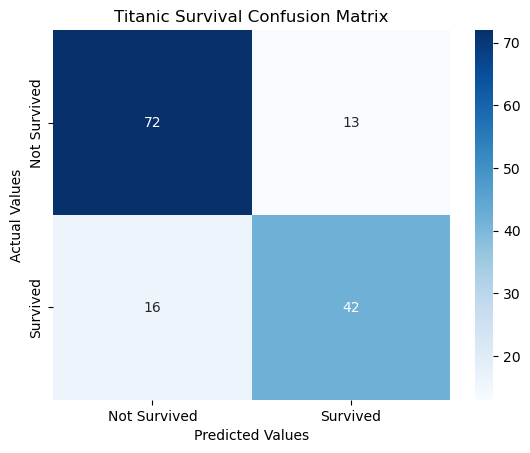

In [18]:
# Plot confusion matrix

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Titanic Survival Confusion Matrix")
plt.show()

In [19]:
# Check overfitting with different tree depths

train_accuracy = []
test_accuracy = []

for depth in range(1, 13):

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)

    train_accuracy.append(accuracy_score(y_train, train_pred))
    test_accuracy.append(accuracy_score(y_test, test_pred))

print("TRAINING ACCURACY:")
print(train_accuracy)

print("\nTESTING ACCURACY:")
print(test_accuracy)

TRAINING ACCURACY:
[0.7793345008756567, 0.7950963222416813, 0.8178633975481612, 0.8476357267950964, 0.8651488616462347, 0.882661996497373, 0.9159369527145359, 0.9246935201401051, 0.9474605954465849, 0.9562171628721541, 0.9649737302977233, 0.968476357267951]

TESTING ACCURACY:
[0.7832167832167832, 0.7762237762237763, 0.8111888111888111, 0.7972027972027972, 0.7622377622377622, 0.7832167832167832, 0.7832167832167832, 0.7902097902097902, 0.7692307692307693, 0.7622377622377622, 0.7692307692307693, 0.7762237762237763]


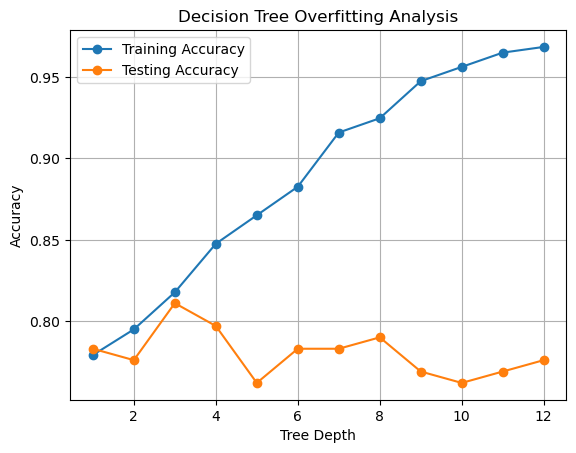

In [20]:
# Plot training and testing accuracy

depths = range(1, 13)

plt.plot(depths, train_accuracy, marker="o", label="Training Accuracy")

plt.plot(depths, test_accuracy, marker="o", label="Testing Accuracy")

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")

plt.title("Decision Tree Overfitting Analysis")

plt.legend()
plt.grid()
plt.show()

In [21]:
# Find important features

importance = model.feature_importances_

print("FEATURE IMPORTANCE")

for feature, value in zip(X.columns, importance):
    print(feature, ":", round(value, 3))

FEATURE IMPORTANCE
pclass : 0.235
sex : 0.545
age : 0.138
fare : 0.082


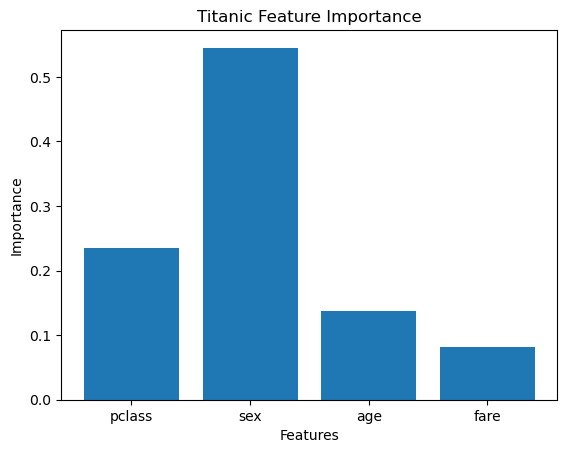

In [22]:
# Plot feature importance

plt.bar(X.columns, importance)

plt.xlabel("Features")
plt.ylabel("Importance")

plt.title("Titanic Feature Importance")

plt.show()

# Titanic Survival Prediction – Project Conclusion

## 1. Introduction
In this project, I developed a Machine Learning model to predict whether a Titanic passenger survived or not using the Decision Tree Classifier.

## 2. Dataset Information
- Dataset: Titanic
- Original records: 891
- Records after cleaning: 714
- Features: Pclass, Sex, Age and Fare
- Target: Survived

## 3. Data Cleaning
- Removed missing values.
- Converted gender into numerical values.
- Male = 0
- Female = 1

## 4. Model Training
I used the Decision Tree Classifier algorithm with max_depth=4.

The dataset was divided into:
- 80% Training data
- 20% Testing data

## 5. Model Evaluation
- Baseline Accuracy: 59.4%
- Decision Tree Accuracy: 79.7%

The model performed better than the baseline.

## 6. Confusion Matrix
- True Negative: 72
- False Positive: 13
- False Negative: 16
- True Positive: 42

## 7. Feature Importance
Gender was the most important feature, followed by passenger class, age and fare.

## 8. Overfitting Analysis
I tested Decision Tree depths from 1 to 12. Training accuracy increased with tree depth, while testing accuracy fluctuated. This showed that deeper trees can overfit the training data.

## 9. Limitations
- Some passenger records were removed because of missing values.
- Only four input features were used.
- The model may not predict every passenger correctly.

## 10. Final Conclusion
Through this project, I learned how to clean data, split datasets, train a Machine Learning model, calculate accuracy, create a confusion matrix and understand overfitting.

The Decision Tree model achieved 79.7% accuracy and performed better than the baseline.
